In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/srujanamannepuli/aligned-faces/Fake/id16_id3_0003/frame_0196.jpg
/kaggle/input/datasets/srujanamannepuli/aligned-faces/Fake/id16_id3_0003/frame_0202.jpg
/kaggle/input/datasets/srujanamannepuli/aligned-faces/Fake/id16_id3_0003/frame_0199.jpg
/kaggle/input/datasets/srujanamannepuli/aligned-faces/Fake/id16_id3_0003/frame_0217.jpg
/kaggle/input/datasets/srujanamannepuli/aligned-faces/Fake/id16_id3_0003/frame_0235.jpg
/kaggle/input/datasets/srujanamannepuli/aligned-faces/Fake/id48_id41_0003/frame_0265.jpg
/kaggle/input/datasets/srujanamannepuli/aligned-faces/Fake/id48_id41_0003/frame_0270.jpg
/kaggle/input/datasets/srujanamannepuli/aligned-faces/Fake/id48_id41_0003/frame_0263.jpg
/kaggle/input/datasets/srujanamannepuli/aligned-faces/Fake/id48_id41_0003/frame_0268.jpg
/kaggle/input/datasets/srujanamannepuli/aligned-faces/Fake/id48_id41_0003/frame_0266.jpg
/kaggle/input/datasets/srujanamannepuli/aligned-faces/Fake/id27_id28_0008/frame_0067.jpg
/kaggle/input/datasets/sru

In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    if "Real" in dirs or "Fake" in dirs:
        print("FOUND:", root)
        print("Subfolders:", dirs)

FOUND: /kaggle/input/datasets/srujanamannepuli/aligned-faces
Subfolders: ['Fake', 'Real']


In [3]:
import os

ALIGNED_ROOT = "/kaggle/input/datasets/srujanamannepuli/aligned-faces"

REAL_DIR = os.path.join(
    ALIGNED_ROOT,
    "Real"
)

FAKE_DIR = os.path.join(
    ALIGNED_ROOT,
    "Fake"
)

print("Aligned root:", ALIGNED_ROOT)
print("Real exists:", os.path.exists(REAL_DIR))
print("Fake exists:", os.path.exists(FAKE_DIR))
print("Real videos:", len(os.listdir(REAL_DIR)))
print("Fake videos:", len(os.listdir(FAKE_DIR)))

Aligned root: /kaggle/input/datasets/srujanamannepuli/aligned-faces
Real exists: True
Fake exists: True
Real videos: 888
Fake videos: 5639


In [4]:
import os
from collections import Counter

def get_frame_files(video_dir):
    return sorted([
        f for f in os.listdir(video_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

real_counts = []
fake_counts = []

for video_id in os.listdir(REAL_DIR):

    video_dir = os.path.join(
        REAL_DIR,
        video_id
    )

    if os.path.isdir(video_dir):
        real_counts.append(
            len(get_frame_files(video_dir))
        )

for video_id in os.listdir(FAKE_DIR):

    video_dir = os.path.join(
        FAKE_DIR,
        video_id
    )

    if os.path.isdir(video_dir):
        fake_counts.append(
            len(get_frame_files(video_dir))
        )

print("Real videos:", len(real_counts))
print("Fake videos:", len(fake_counts))

print("\nReal frame-count distribution:")
print(Counter(real_counts))

print("\nFake frame-count distribution:")
print(Counter(fake_counts))

print("\nMaximum Real frames:", max(real_counts))
print("Maximum Fake frames:", max(fake_counts))

Real videos: 888
Fake videos: 5639

Real frame-count distribution:
Counter({5: 879, 4: 7, 3: 1, 2: 1})

Fake frame-count distribution:
Counter({5: 5634, 4: 5})

Maximum Real frames: 5
Maximum Fake frames: 5


In [5]:
import pandas as pd
import os

records = []

for label_name, label_value, root_dir in [
    ("Real", 0, REAL_DIR),
    ("Fake", 1, FAKE_DIR)
]:

    for video_id in sorted(os.listdir(root_dir)):

        video_dir = os.path.join(
            root_dir,
            video_id
        )

        if not os.path.isdir(video_dir):
            continue

        frame_files = sorted([
            f for f in os.listdir(video_dir)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        ])

        # Need at least 3 frames for
        # first-middle-last training strategy
        if len(frame_files) >= 3:

            records.append({
                "video_id": video_id,
                "label": label_value,
                "label_name": label_name,
                "video_dir": video_dir,
                "num_frames": len(frame_files)
            })

videos_df = pd.DataFrame(records)

print("Total usable videos:", len(videos_df))

print("\nClass distribution:")
print(videos_df["label_name"].value_counts())

print("\nFrame distribution:")
print(videos_df["num_frames"].value_counts().sort_index())

Total usable videos: 6526

Class distribution:
label_name
Fake    5639
Real     887
Name: count, dtype: int64

Frame distribution:
num_frames
3       1
4      12
5    6513
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import StratifiedKFold

N_FOLDS = 10

skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=42
)

videos_df["fold"] = -1

for fold, (_, val_idx) in enumerate(
    skf.split(
        videos_df,
        videos_df["label"]
    ),
    start=1
):
    
    videos_df.loc[
        val_idx,
        "fold"
    ] = fold

print("Fold assignment completed.")
print(
    videos_df["fold"]
    .value_counts()
    .sort_index()
)

Fold assignment completed.
fold
1     653
2     653
3     653
4     653
5     653
6     653
7     652
8     652
9     652
10    652
Name: count, dtype: int64


In [7]:
for fold in range(1, 11):

    fold_data = videos_df[
        videos_df["fold"] == fold
    ]

    real_count = (
        fold_data["label"] == 0
    ).sum()

    fake_count = (
        fold_data["label"] == 1
    ).sum()

    print(
        f"Fold {fold}: "
        f"Total={len(fold_data)}, "
        f"Real={real_count}, "
        f"Fake={fake_count}"
    )

Fold 1: Total=653, Real=89, Fake=564
Fold 2: Total=653, Real=89, Fake=564
Fold 3: Total=653, Real=89, Fake=564
Fold 4: Total=653, Real=89, Fake=564
Fold 5: Total=653, Real=89, Fake=564
Fold 6: Total=653, Real=89, Fake=564
Fold 7: Total=652, Real=89, Fake=563
Fold 8: Total=652, Real=88, Fake=564
Fold 9: Total=652, Real=88, Fake=564
Fold 10: Total=652, Real=88, Fake=564


In [8]:
def get_frame_files(video_dir):
    return sorted([
        f for f in os.listdir(video_dir)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ])


def get_training_frames(frame_files):
    """
    Training:
    First + Middle + Last
    """

    n = len(frame_files)

    if n < 3:
        return frame_files

    indices = [
        0,
        n // 2,
        n - 1
    ]

    return [
        frame_files[i]
        for i in indices
    ]


def get_validation_frames(frame_files):
    """
    Validation:
    All available frames (maximum 5)
    """

    return frame_files[:5]

In [9]:
sample_row = videos_df.iloc[0]

sample_frames = get_frame_files(
    sample_row["video_dir"]
)

print("Video:", sample_row["video_id"])
print("All frames:", sample_frames)

print(
    "\nTraining frames:",
    get_training_frames(sample_frames)
)

print(
    "\nValidation frames:",
    get_validation_frames(sample_frames)
)

Video: 00000
All frames: ['frame_0048.jpg', 'frame_0065.jpg', 'frame_0066.jpg', 'frame_0242.jpg', 'frame_0302.jpg']

Training frames: ['frame_0048.jpg', 'frame_0066.jpg', 'frame_0302.jpg']

Validation frames: ['frame_0048.jpg', 'frame_0065.jpg', 'frame_0066.jpg', 'frame_0242.jpg', 'frame_0302.jpg']


In [10]:
import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset
from PIL import Image
import pywt


class DWTFaceDataset(Dataset):

    def __init__(
        self,
        dataframe,
        mode="train",
        image_size=224
    ):

        self.df = dataframe.reset_index(drop=True)
        self.mode = mode
        self.image_size = image_size

        self.samples = []

        # ==========================================
        # Build frame-level samples
        # ==========================================

        for _, row in self.df.iterrows():

            frame_files = get_frame_files(
                row["video_dir"]
            )

            # -------------------------------
            # Training:
            # First + Middle + Last
            # -------------------------------

            if mode == "train":

                selected_frames = get_training_frames(
                    frame_files
                )

            # -------------------------------
            # Validation:
            # All available frames (max 5)
            # -------------------------------

            else:

                selected_frames = get_validation_frames(
                    frame_files
                )

            for frame_file in selected_frames:

                self.samples.append({

                    "video_id": row["video_id"],

                    "frame_file": frame_file,

                    "video_dir": row["video_dir"],

                    "label": row["label"]

                })

        print(
            f"{mode.upper()} samples:",
            len(self.samples)
        )

    # ==========================================
    # Dataset length
    # ==========================================

    def __len__(self):

        return len(self.samples)

    # ==========================================
    # Get one sample
    # ==========================================

    def __getitem__(self, idx):

        sample = self.samples[idx]

        image_path = os.path.join(
            sample["video_dir"],
            sample["frame_file"]
        )

        # ======================================
        # Load RGB image
        # ======================================

        image = Image.open(
            image_path
        ).convert("RGB")

        image = image.resize(
            (
                self.image_size,
                self.image_size
            ),
            Image.Resampling.BILINEAR
        )

        image_np = np.asarray(
            image
        ).astype(np.float32)

        # ======================================
        # RGB → DWT
        # ======================================

        LL_channels = []
        LH_channels = []
        HL_channels = []
        HH_channels = []

        for c in range(3):

            channel = image_np[:, :, c]

            LL, (LH, HL, HH) = pywt.dwt2(
                channel,
                "haar"
            )

            LL_channels.append(LL)
            LH_channels.append(LH)
            HL_channels.append(HL)
            HH_channels.append(HH)

        # ======================================
        # Stack RGB channels
        # ======================================

        LL = np.stack(
            LL_channels,
            axis=-1
        )

        LH = np.stack(
            LH_channels,
            axis=-1
        )

        HL = np.stack(
            HL_channels,
            axis=-1
        )

        HH = np.stack(
            HH_channels,
            axis=-1
        )

        # ======================================
        # Weighted Frequency Fusion
        # ======================================

        fused = (
            0.40 * LL +
            0.20 * LH +
            0.20 * HL +
            0.20 * HH
        )

        # ======================================
        # Normalize to 0–255
        # ======================================

        fused_min = fused.min()
        fused_max = fused.max()

        fused = (
            (fused - fused_min) /
            (fused_max - fused_min + 1e-8)
        ) * 255.0

        fused = np.clip(
            fused,
            0,
            255
        ).astype(np.uint8)

        # ======================================
        # Convert to Tensor
        # ======================================

        fused = torch.from_numpy(
            fused
        ).permute(
            2,
            0,
            1
        ).float() / 255.0

        # At this point:
        # [3, 112, 112]

        # ======================================
        # Resize DWT representation
        # 112 × 112 → 224 × 224
        # ======================================

        fused = F.interpolate(
            fused.unsqueeze(0),
            size=(
                self.image_size,
                self.image_size
            ),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)

        # ======================================
        # Label
        # ======================================

        label = torch.tensor(
            sample["label"],
            dtype=torch.long
        )

        return fused, label

In [11]:
fold = 1

train_df = videos_df[
    videos_df["fold"] != fold
].copy()

val_df = videos_df[
    videos_df["fold"] == fold
].copy()

print("Fold:", fold)
print("Training videos:", len(train_df))
print("Validation videos:", len(val_df))

train_dataset = DWTFaceDataset(
    train_df,
    mode="train"
)

val_dataset = DWTFaceDataset(
    val_df,
    mode="val"
)

Fold: 1
Training videos: 5873
Validation videos: 653
TRAIN samples: 17619
VAL samples: 3263


In [12]:
sample_image, sample_label = train_dataset[0]

print("DWT image shape:", sample_image.shape)
print("Label:", sample_label)

print(
    "Value range:",
    sample_image.min().item(),
    "to",
    sample_image.max().item()
)

DWT image shape: torch.Size([3, 224, 224])
Label: tensor(0)
Value range: 0.0 to 0.9980392456054688


In [13]:
import torch
from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train samples: 17619
Validation samples: 3263
Train batches: 1102
Validation batches: 204


In [ ]:
dwt_batch, label_batch = next(iter(train_loader))

print("DWT batch:", dwt_batch.shape)
print("Labels:", label_batch.shape)

In [15]:
import torch
import torch.nn as nn
from torchvision.models import (
    efficientnet_b4,
    EfficientNet_B4_Weights
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

weights = EfficientNet_B4_Weights.DEFAULT

model = efficientnet_b4(
    weights=weights
)

# Replace ImageNet classifier
num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    num_features,
    2
)

model = model.to(device)

print("EfficientNet-B4 ready")
print("Classifier:", model.classifier)

Device: cuda
EfficientNet-B4 ready
Classifier: Sequential(
  (0): Dropout(p=0.4, inplace=True)
  (1): Linear(in_features=1792, out_features=2, bias=True)
)


In [16]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 1e-05
)


In [17]:
model.eval()

with torch.no_grad():

    dwt_batch = dwt_batch.to(device)

    logits = model(
        dwt_batch
    )

print("Input:", dwt_batch.shape)
print("Logits:", logits.shape)

Input: torch.Size([16, 3, 224, 224])
Logits: torch.Size([16, 2])


In [18]:
from sklearn.metrics import accuracy_score

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    device
):

    model.train()

    running_loss = 0.0
    all_labels = []
    all_preds = []

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        logits = model(images)

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * labels.size(0)
        )

        preds = torch.argmax(
            logits,
            dim=1
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        all_preds.extend(
            preds.detach().cpu().numpy()
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    return epoch_loss, accuracy

In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import numpy as np


def validate_dwt(
    model,
    dataset,
    device
):

    model.eval()

    # video_id → probabilities
    video_probs = {}

    # video_id → label
    video_labels = {}

    total_loss = 0.0
    criterion_eval = nn.CrossEntropyLoss()

    with torch.no_grad():

        for sample in dataset:

            image, label = sample

            image = image.unsqueeze(0).to(device)

            label_tensor = torch.tensor(
                [int(label)],
                dtype=torch.long,
                device=device
            )

            logits = model(image)

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            fake_probability = (
                probabilities[0, 1]
                .item()
            )

            # Get video ID from dataset sample
            sample_info = dataset.samples[
                len(video_probs)
            ] if False else None

    # ------------------------------------
    # Proper video-level validation
    # ------------------------------------

    video_probs = {}
    video_labels = {}

    with torch.no_grad():

        for idx in range(len(dataset)):

            sample_info = dataset.samples[idx]

            image_path = os.path.join(
                sample_info["video_dir"],
                sample_info["frame_file"]
            )

            image = Image.open(
                image_path
            ).convert("RGB")

            image = image.resize(
                (224, 224),
                Image.Resampling.BILINEAR
            )

            image_np = np.asarray(
                image
            ).astype(np.float32)

            # DWT
            LL_channels = []
            LH_channels = []
            HL_channels = []
            HH_channels = []

            for c in range(3):

                channel = image_np[:, :, c]

                LL, (LH, HL, HH) = pywt.dwt2(
                    channel,
                    "haar"
                )

                LL_channels.append(LL)
                LH_channels.append(LH)
                HL_channels.append(HL)
                HH_channels.append(HH)

            LL = np.stack(
                LL_channels,
                axis=-1
            )

            LH = np.stack(
                LH_channels,
                axis=-1
            )

            HL = np.stack(
                HL_channels,
                axis=-1
            )

            HH = np.stack(
                HH_channels,
                axis=-1
            )

            fused = (
                0.40 * LL +
                0.20 * LH +
                0.20 * HL +
                0.20 * HH
            )

            fused_min = fused.min()
            fused_max = fused.max()

            fused = (
                (fused - fused_min) /
                (fused_max - fused_min + 1e-8)
            ) * 255.0

            fused = np.clip(
                fused,
                0,
                255
            ).astype(np.uint8)

            fused = torch.from_numpy(
                fused
            ).permute(
                2, 0, 1
            ).float() / 255.0

            fused = F.interpolate(
                fused.unsqueeze(0),
                size=(224, 224),
                mode="bilinear",
                align_corners=False
            ).to(device)

            logits = model(fused)

            prob = torch.softmax(
                logits,
                dim=1
            )[0, 1].item()

            video_id = sample_info[
                "video_id"
            ]

            label = int(
                sample_info["label"]
            )

            video_probs.setdefault(
                video_id,
                []
            ).append(prob)

            video_labels[
                video_id
            ] = label

    # ------------------------------------
    # Aggregate 5 frame probabilities
    # ------------------------------------

    y_true = []
    y_prob = []

    for video_id in video_probs:

        mean_probability = np.mean(
            video_probs[video_id]
        )

        y_prob.append(
            mean_probability
        )

        y_true.append(
            video_labels[video_id]
        )

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)

    y_pred = (
        y_prob >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    return (
        accuracy,
        precision,
        recall,
        f1,
        auc
    )

In [22]:
NUM_EPOCHS = 5

fold1_history = []

best_fold_f1 = 0.0

for epoch in range(NUM_EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device
    )

    (
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        val_auc
    ) = validate_dwt(
        model,
        val_dataset,
        device
    )

    print(
        f"\nEpoch {epoch + 1}/{NUM_EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f}"
    )

    print(
        f"Val Accuracy: {val_acc:.4f}"
    )

    print(
        f"Precision: {val_precision:.4f} | "
        f"Recall: {val_recall:.4f} | "
        f"F1: {val_f1:.4f} | "
        f"AUC: {val_auc:.4f}"
    )

    fold1_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "precision": val_precision,
        "recall": val_recall,
        "f1": val_f1,
        "auc": val_auc
    })

    if val_f1 > best_fold_f1:

        best_fold_f1 = val_f1

        torch.save(
            model.state_dict(),
            "/kaggle/working/fold1_best_dwt.pth"
        )

        print("🔥 Fold 1 best model saved!")


Epoch 1/5
Train Loss: 0.2603 | Train Accuracy: 0.9004
Val Accuracy: 0.9617
Precision: 0.9576 | Recall: 1.0000 | F1: 0.9783 | AUC: 0.9847
🔥 Fold 1 best model saved!

Epoch 2/5
Train Loss: 0.1216 | Train Accuracy: 0.9541
Val Accuracy: 0.9694
Precision: 0.9658 | Recall: 1.0000 | F1: 0.9826 | AUC: 0.9920
🔥 Fold 1 best model saved!


KeyboardInterrupt: 

In [23]:
import os
import numpy as np
import pandas as pd
import pywt
from PIL import Image
from tqdm.auto import tqdm

CACHE_ROOT = "/kaggle/working/dwt_cache"
os.makedirs(CACHE_ROOT, exist_ok=True)

CACHE_SIZE = 112

def compute_dwt_fused(image_path):

    image = Image.open(image_path).convert("RGB")
    image = image.resize(
        (224, 224),
        Image.Resampling.BILINEAR
    )

    image = np.asarray(image).astype(np.float32)

    LL_list = []
    LH_list = []
    HL_list = []
    HH_list = []

    for c in range(3):

        LL, (LH, HL, HH) = pywt.dwt2(
            image[:, :, c],
            "haar"
        )

        LL_list.append(LL)
        LH_list.append(LH)
        HL_list.append(HL)
        HH_list.append(HH)

    LL = np.stack(LL_list, axis=-1)
    LH = np.stack(LH_list, axis=-1)
    HL = np.stack(HL_list, axis=-1)
    HH = np.stack(HH_list, axis=-1)

    # Weighted frequency fusion
    fused = (
        0.40 * LL +
        0.20 * LH +
        0.20 * HL +
        0.20 * HH
    )

    # Normalize
    fused_min = fused.min()
    fused_max = fused.max()

    fused = (
        (fused - fused_min) /
        (fused_max - fused_min + 1e-8)
    ) * 255.0

    fused = np.clip(
        fused,
        0,
        255
    ).astype(np.uint8)

    return fused


# ---------------------------------------
# Create cache for every aligned frame
# ---------------------------------------

cache_records = []

for _, row in tqdm(
    videos_df.iterrows(),
    total=len(videos_df),
    desc="Creating DWT cache"
):

    video_id = row["video_id"]
    video_dir = row["video_dir"]
    label = row["label"]

    frame_files = get_frame_files(video_dir)

    for frame_file in frame_files:

        image_path = os.path.join(
            video_dir,
            frame_file
        )

        fused = compute_dwt_fused(
            image_path
        )

        cache_name = (
            f"{label}_{video_id}_{frame_file}"
            .replace("/", "_")
            .replace("\\", "_")
        )

        cache_path = os.path.join(
            CACHE_ROOT,
            cache_name + ".npy"
        )

        np.save(
            cache_path,
            fused
        )

        cache_records.append({
            "video_id": video_id,
            "frame_file": frame_file,
            "label": label,
            "cache_path": cache_path
        })


cache_df = pd.DataFrame(
    cache_records
)

cache_df.to_csv(
    "/kaggle/working/dwt_cache_index.csv",
    index=False
)

print("\n✅ DWT CACHE COMPLETED")
print("Total cached frames:", len(cache_df))
print("Cache location:", CACHE_ROOT)

Creating DWT cache:   0%|          | 0/6526 [00:00<?, ?it/s]


✅ DWT CACHE COMPLETED
Total cached frames: 32616
Cache location: /kaggle/working/dwt_cache


In [24]:
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


class FastDWTDataset(Dataset):

    def __init__(
        self,
        dataframe,
        mode="train"
    ):

        self.mode = mode
        self.samples = []

        for video_id, group in dataframe.groupby(
            "video_id"
        ):

            group = group.sort_values(
                "frame_file"
            )

            frames = group.to_dict(
                "records"
            )

            if mode == "train":

                # First, middle, last
                n = len(frames)

                indices = [
                    0,
                    n // 2,
                    n - 1
                ]

                selected = [
                    frames[i]
                    for i in indices
                ]

            else:

                # All available frames, max 5
                selected = frames[:5]

            for sample in selected:

                self.samples.append(
                    sample
                )

        print(
            f"{mode.upper()} samples:",
            len(self.samples)
        )

    def __len__(self):

        return len(self.samples)

    def __getitem__(self, idx):

        sample = self.samples[idx]

        # Cached DWT = 112 × 112 × 3
        image = np.load(
            sample["cache_path"]
        )

        image = torch.from_numpy(
            image
        ).permute(
            2, 0, 1
        ).float() / 255.0

        # 112 → 224
        image = F.interpolate(
            image.unsqueeze(0),
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)

        label = torch.tensor(
            sample["label"],
            dtype=torch.long
        )

        return (
            image,
            label,
            sample["video_id"]
        )

In [25]:
fold = 1

train_videos = videos_df[
    videos_df["fold"] != fold
]

val_videos = videos_df[
    videos_df["fold"] == fold
]

train_cache_df = cache_df[
    cache_df["video_id"].isin(
        train_videos["video_id"]
    )
]

val_cache_df = cache_df[
    cache_df["video_id"].isin(
        val_videos["video_id"]
    )
]

train_dataset = FastDWTDataset(
    train_cache_df,
    mode="train"
)

val_dataset = FastDWTDataset(
    val_cache_df,
    mode="val"
)

TRAIN samples: 17619
VAL samples: 3263


In [26]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train samples: 17619
Validation samples: 3263
Train batches: 551
Validation batches: 102


In [27]:
images, labels, video_ids = next(
    iter(train_loader)
)

print("Images:", images.shape)
print("Labels:", labels.shape)
print("First video IDs:", video_ids[:5])

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
First video IDs: ('id31_id9_0004', 'id26_id31_0009', 'id17_id9_0000', 'id2_id17_0004', 'id4_id9_0003')


In [28]:
import torch
import torch.nn as nn
from torchvision.models import (
    efficientnet_b4,
    EfficientNet_B4_Weights
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

weights = EfficientNet_B4_Weights.DEFAULT

model = efficientnet_b4(
    weights=weights
)

# Binary classification
num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    num_features,
    2
)

model = model.to(device)

# Faster GPU memory layout
if device.type == "cuda":
    model = model.to(
        memory_format=torch.channels_last
    )

print("EfficientNet-B4 ready")
print("Classifier:", model.classifier)

Device: cuda
EfficientNet-B4 ready
Classifier: Sequential(
  (0): Dropout(p=0.4, inplace=True)
  (1): Linear(in_features=1792, out_features=2, bias=True)
)


In [29]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

print("Optimizer: Adam")
print("Learning rate: 1e-4")
print("AMP enabled:", device.type == "cuda")

Optimizer: Adam
Learning rate: 1e-4
AMP enabled: True


In [30]:
def train_one_epoch_fast(
    model,
    loader,
    optimizer,
    criterion,
    scaler,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels, _ in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        if device.type == "cuda":
            images = images.to(
                memory_format=torch.channels_last
            )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += (
            loss.item() * labels.size(0)
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = (
        running_loss / total
    )

    epoch_accuracy = (
        correct / total
    )

    return epoch_loss, epoch_accuracy

In [31]:
import time

start_time = time.time()

train_loss, train_accuracy = train_one_epoch_fast(
    model,
    train_loader,
    optimizer,
    criterion,
    scaler,
    device
)

elapsed = time.time() - start_time

print("\n==============================")
print("FOLD 1 TRAINING TEST")
print("==============================")
print(f"Loss     : {train_loss:.4f}")
print(f"Accuracy : {train_accuracy:.4f}")
print(
    f"Time     : {elapsed/60:.2f} minutes"
)


FOLD 1 TRAINING TEST
Loss     : 0.3343
Accuracy : 0.8764
Time     : 2.18 minutes


In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import numpy as np
import torch


def validate_fast(
    model,
    loader,
    device
):

    model.eval()

    # video_id -> list of fake probabilities
    video_probs = {}

    # video_id -> true label
    video_labels = {}

    with torch.no_grad():

        for images, labels, video_ids in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            if device.type == "cuda":
                images = images.to(
                    memory_format=torch.channels_last
                )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                logits = model(images)

            probabilities = torch.softmax(
                logits.float(),
                dim=1
            )

            fake_probs = probabilities[
                :, 1
            ].cpu().numpy()

            labels_np = labels.numpy()

            # --------------------------------
            # Store frame probabilities
            # --------------------------------

            for i, video_id in enumerate(
                video_ids
            ):

                video_probs.setdefault(
                    video_id,
                    []
                ).append(
                    float(fake_probs[i])
                )

                video_labels[
                    video_id
                ] = int(labels_np[i])

    # ========================================
    # Video-level aggregation
    # ========================================

    y_true = []
    y_prob = []

    for video_id in video_probs:

        # Average probability of all
        # available validation frames
        mean_prob = np.mean(
            video_probs[video_id]
        )

        y_prob.append(
            mean_prob
        )

        y_true.append(
            video_labels[video_id]
        )

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)

    y_pred = (
        y_prob >= 0.5
    ).astype(int)

    # ========================================
    # Metrics
    # ========================================

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "auc": auc,
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred
    }

In [34]:
import time

start_time = time.time()

val_results = validate_fast(
    model,
    val_loader,
    device
)

elapsed = time.time() - start_time

print("\n==============================")
print("FOLD 1 VALIDATION")
print("==============================")

print(
    f"Accuracy  : {val_results['accuracy']:.4f}"
)

print(
    f"Precision : {val_results['precision']:.4f}"
)

print(
    f"Recall    : {val_results['recall']:.4f}"
)

print(
    f"F1 Score  : {val_results['f1']:.4f}"
)

print(
    f"AUC       : {val_results['auc']:.4f}"
)

print(
    f"Validation time: {elapsed/60:.2f} minutes"
)


FOLD 1 VALIDATION
Accuracy  : 0.9250
Precision : 0.9228
Recall    : 0.9965
F1 Score  : 0.9582
AUC       : 0.9561
Validation time: 0.25 minutes


In [35]:
NUM_EPOCHS = 5

fold1_history = []
best_f1 = 0.0

for epoch in range(NUM_EPOCHS):

    start_time = time.time()

    # -----------------------------
    # Training
    # -----------------------------

    train_loss, train_acc = train_one_epoch_fast(
        model,
        train_loader,
        optimizer,
        criterion,
        scaler,
        device
    )

    # -----------------------------
    # Validation
    # -----------------------------

    val_results = validate_fast(
        model,
        val_loader,
        device
    )

    epoch_time = (
        time.time() - start_time
    )

    print(
        f"\nEpoch {epoch + 1}/{NUM_EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f}"
    )

    print(
        f"Val Accuracy: "
        f"{val_results['accuracy']:.4f}"
    )

    print(
        f"Precision: "
        f"{val_results['precision']:.4f} | "
        f"Recall: "
        f"{val_results['recall']:.4f}"
    )

    print(
        f"F1: "
        f"{val_results['f1']:.4f} | "
        f"AUC: "
        f"{val_results['auc']:.4f}"
    )

    print(
        f"Epoch Time: "
        f"{epoch_time/60:.2f} min"
    )

    # -----------------------------
    # Save history
    # -----------------------------

    fold1_history.append({

        "epoch": epoch + 1,

        "train_loss": train_loss,

        "train_accuracy": train_acc,

        "val_accuracy":
            val_results["accuracy"],

        "precision":
            val_results["precision"],

        "recall":
            val_results["recall"],

        "f1":
            val_results["f1"],

        "auc":
            val_results["auc"],

        "epoch_time_min":
            epoch_time / 60
    })

    # -----------------------------
    # Save best model
    # -----------------------------

    if val_results["f1"] > best_f1:

        best_f1 = val_results["f1"]

        torch.save(
            {
                "fold": 1,
                "epoch": epoch + 1,
                "model_state_dict":
                    model.state_dict(),
                "optimizer_state_dict":
                    optimizer.state_dict(),
                "val_accuracy":
                    val_results["accuracy"],
                "precision":
                    val_results["precision"],
                "recall":
                    val_results["recall"],
                "f1":
                    val_results["f1"],
                "auc":
                    val_results["auc"]
            },
            "/kaggle/working/fold1_best_dwt.pth"
        )

        print("🔥 Fold-1 best model saved!")


Epoch 1/5
Train Loss: 0.1575 | Train Accuracy: 0.9405
Val Accuracy: 0.9587
Precision: 0.9543 | Recall: 1.0000
F1: 0.9766 | AUC: 0.9939
Epoch Time: 1.81 min
🔥 Fold-1 best model saved!

Epoch 2/5
Train Loss: 0.0785 | Train Accuracy: 0.9720
Val Accuracy: 0.9632
Precision: 0.9592 | Recall: 1.0000
F1: 0.9792 | AUC: 0.9967
Epoch Time: 1.80 min
🔥 Fold-1 best model saved!

Epoch 3/5
Train Loss: 0.0487 | Train Accuracy: 0.9823
Val Accuracy: 0.9587
Precision: 0.9543 | Recall: 1.0000
F1: 0.9766 | AUC: 0.9950
Epoch Time: 1.79 min

Epoch 4/5
Train Loss: 0.0357 | Train Accuracy: 0.9869
Val Accuracy: 0.9678
Precision: 0.9641 | Recall: 1.0000
F1: 0.9817 | AUC: 0.9939
Epoch Time: 1.80 min
🔥 Fold-1 best model saved!

Epoch 5/5
Train Loss: 0.0265 | Train Accuracy: 0.9907
Val Accuracy: 0.9786
Precision: 0.9758 | Recall: 1.0000
F1: 0.9877 | AUC: 0.9945
Epoch Time: 1.79 min
🔥 Fold-1 best model saved!


In [36]:
import os
import pandas as pd
import torch
import time

RESULT_DIR = "/kaggle/working/10fold_dwt_results"

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

# Save Fold-1 history already obtained
pd.DataFrame(
    fold1_history
).to_csv(
    os.path.join(
        RESULT_DIR,
        "fold1_history.csv"
    ),
    index=False
)

print("Fold-1 saved.")

Fold-1 saved.


In [37]:
def create_fresh_efficientnet():

    weights = EfficientNet_B4_Weights.DEFAULT

    new_model = efficientnet_b4(
        weights=weights
    )

    num_features = (
        new_model.classifier[1].in_features
    )

    new_model.classifier[1] = nn.Linear(
        num_features,
        2
    )

    new_model = new_model.to(device)

    if device.type == "cuda":
        new_model = new_model.to(
            memory_format=torch.channels_last
        )

    return new_model

In [38]:
all_fold_results = []

# Fold 1 result
best_fold1 = max(
    fold1_history,
    key=lambda x: x["f1"]
)

all_fold_results.append({
    "fold": 1,
    "accuracy": best_fold1["val_accuracy"],
    "precision": best_fold1["precision"],
    "recall": best_fold1["recall"],
    "f1": best_fold1["f1"],
    "auc": best_fold1["auc"]
})


for fold in range(2, 11):

    print("\n")
    print("=" * 60)
    print(f"STARTING FOLD {fold}/10")
    print("=" * 60)

    # ---------------------------------
    # Split videos
    # ---------------------------------

    train_videos = videos_df[
        videos_df["fold"] != fold
    ]

    val_videos = videos_df[
        videos_df["fold"] == fold
    ]

    # ---------------------------------
    # Cached DWT data
    # ---------------------------------

    train_cache_df = cache_df[
        cache_df["video_id"].isin(
            train_videos["video_id"]
        )
    ]

    val_cache_df = cache_df[
        cache_df["video_id"].isin(
            val_videos["video_id"]
        )
    ]

    train_dataset = FastDWTDataset(
        train_cache_df,
        mode="train"
    )

    val_dataset = FastDWTDataset(
        val_cache_df,
        mode="val"
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        num_workers=4,
        pin_memory=True,
        persistent_workers=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=4,
        pin_memory=True,
        persistent_workers=True
    )

    # ---------------------------------
    # FRESH MODEL
    # ---------------------------------

    model = create_fresh_efficientnet()

    # ---------------------------------
    # FRESH OPTIMIZER
    # ---------------------------------

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-5
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(device.type == "cuda")
    )

    # ---------------------------------
    # Training
    # ---------------------------------

    NUM_EPOCHS = 5

    best_f1 = 0.0
    best_result = None

    for epoch in range(NUM_EPOCHS):

        epoch_start = time.time()

        train_loss, train_acc = (
            train_one_epoch_fast(
                model,
                train_loader,
                optimizer,
                criterion,
                scaler,
                device
            )
        )

        val_results = validate_fast(
            model,
            val_loader,
            device
        )

        epoch_time = (
            time.time() - epoch_start
        )

        print(
            f"\nFold {fold} | "
            f"Epoch {epoch+1}/{NUM_EPOCHS}"
        )

        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f}"
        )

        print(
            f"Val Acc: "
            f"{val_results['accuracy']:.4f} | "
            f"Precision: "
            f"{val_results['precision']:.4f}"
        )

        print(
            f"Recall: "
            f"{val_results['recall']:.4f} | "
            f"F1: "
            f"{val_results['f1']:.4f} | "
            f"AUC: "
            f"{val_results['auc']:.4f}"
        )

        print(
            f"Time: "
            f"{epoch_time/60:.2f} min"
        )

        # -----------------------------
        # Best model
        # -----------------------------

        if val_results["f1"] > best_f1:

            best_f1 = val_results["f1"]

            best_result = {
                "fold": fold,
                "accuracy":
                    val_results["accuracy"],
                "precision":
                    val_results["precision"],
                "recall":
                    val_results["recall"],
                "f1":
                    val_results["f1"],
                "auc":
                    val_results["auc"]
            }

            torch.save(
                {
                    "fold": fold,
                    "model_state_dict":
                        model.state_dict(),
                    "optimizer_state_dict":
                        optimizer.state_dict(),
                    "metrics":
                        best_result
                },
                os.path.join(
                    RESULT_DIR,
                    f"fold_{fold}_best.pth"
                )
            )

            print(
                "🔥 Best model saved!"
            )

    # ---------------------------------
    # Save fold result
    # ---------------------------------

    all_fold_results.append(
        best_result
    )

    pd.DataFrame(
        all_fold_results
    ).to_csv(
        os.path.join(
            RESULT_DIR,
            "fold_results_progress.csv"
        ),
        index=False
    )

    print(
        f"\n✅ Fold {fold} completed."
    )



STARTING FOLD 2/10
TRAIN samples: 17619
VAL samples: 3263

Fold 2 | Epoch 1/5
Train Loss: 0.3406 | Train Acc: 0.8738
Val Acc: 0.9188 | Precision: 0.9168
Recall: 0.9965 | F1: 0.9550 | AUC: 0.9542
Time: 1.82 min
🔥 Best model saved!

Fold 2 | Epoch 2/5
Train Loss: 0.1648 | Train Acc: 0.9369
Val Acc: 0.9694 | Precision: 0.9658
Recall: 1.0000 | F1: 0.9826 | AUC: 0.9915
Time: 1.80 min
🔥 Best model saved!

Fold 2 | Epoch 3/5
Train Loss: 0.0882 | Train Acc: 0.9676
Val Acc: 0.9694 | Precision: 0.9658
Recall: 1.0000 | F1: 0.9826 | AUC: 0.9941
Time: 1.80 min

Fold 2 | Epoch 4/5
Train Loss: 0.0533 | Train Acc: 0.9804
Val Acc: 0.9786 | Precision: 0.9791
Recall: 0.9965 | F1: 0.9877 | AUC: 0.9944
Time: 1.80 min
🔥 Best model saved!

Fold 2 | Epoch 5/5
Train Loss: 0.0320 | Train Acc: 0.9887
Val Acc: 0.9801 | Precision: 0.9775
Recall: 1.0000 | F1: 0.9886 | AUC: 0.9945
Time: 1.80 min
🔥 Best model saved!

✅ Fold 2 completed.


STARTING FOLD 3/10
TRAIN samples: 17619
VAL samples: 3263

Fold 3 | Epoch 1/5

In [39]:
fold_results_df = pd.DataFrame(
    all_fold_results
)

print(fold_results_df)

fold_results_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "DWT_10fold_results.csv"
    ),
    index=False
)

   fold  accuracy  precision    recall        f1       auc
0     1  0.978560   0.975779  1.000000  0.987741  0.994521
1     2  0.980092   0.977470  1.000000  0.988606  0.994502
2     3  0.972435   0.972318  0.996454  0.984238  0.994292
3     4  0.977029   0.975737  0.998227  0.986854  0.994920
4     5  0.984686   0.982578  1.000000  0.991213  0.996952
5     6  0.978560   0.980769  0.994681  0.987676  0.997071
6     7  0.981595   0.979130  1.000000  0.989455  0.996986
7     8  0.984663   0.985965  0.996454  0.991182  0.996293
8     9  0.970859   0.967410  1.000000  0.983435  0.989261
9    10  0.969325   0.965753  1.000000  0.982578  0.995064


In [40]:
metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auc"
]

summary = []

for metric in metrics:

    summary.append({
        "Metric": metric.upper(),
        "Mean": fold_results_df[metric].mean(),
        "Std": fold_results_df[metric].std(
            ddof=1
        )
    })

summary_df = pd.DataFrame(
    summary
)

print("\n==============================")
print("DWT 10-FOLD SUMMARY")
print("==============================")

print(summary_df)

summary_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "DWT_10fold_mean_std.csv"
    ),
    index=False
)


DWT 10-FOLD SUMMARY
      Metric      Mean       Std
0   ACCURACY  0.977780  0.005423
1  PRECISION  0.976291  0.006402
2     RECALL  0.998582  0.002013
3         F1  0.987298  0.003053
4        AUC  0.994986  0.002301


In [41]:
# ============================================================
# DWT 10-FOLD RESULTS - SAVE ALL TABLES & FIGURES
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shutil

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    precision_recall_curve
)

# ------------------------------------------------------------
# 1. Create results folder
# ------------------------------------------------------------

PLOT_DIR = "/kaggle/working/DWT_10Fold_Final_Results"

os.makedirs(PLOT_DIR, exist_ok=True)

print("Results folder:", PLOT_DIR)


# ------------------------------------------------------------
# 2. Save fold-wise results
# ------------------------------------------------------------

fold_results_df = pd.DataFrame(
    all_fold_results
)

fold_results_df.to_csv(
    os.path.join(
        PLOT_DIR,
        "DWT_10Fold_Foldwise_Results.csv"
    ),
    index=False
)

print("✅ Fold-wise results saved")


# ------------------------------------------------------------
# 3. Mean ± SD table
# ------------------------------------------------------------

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auc"
]

summary_rows = []

for metric in metrics:

    mean_value = (
        fold_results_df[metric]
        .mean()
    )

    std_value = (
        fold_results_df[metric]
        .std(ddof=1)
    )

    summary_rows.append({

        "Metric": metric.upper(),

        "Mean": mean_value,

        "Standard_Deviation": std_value,

        "Mean_Plus_Minus_SD":
            f"{mean_value:.4f} ± {std_value:.4f}"

    })


summary_df = pd.DataFrame(
    summary_rows
)

summary_df.to_csv(
    os.path.join(
        PLOT_DIR,
        "DWT_10Fold_Mean_SD.csv"
    ),
    index=False
)

print("\n==============================")
print("DWT 10-FOLD MEAN ± SD")
print("==============================")

print(summary_df)


# ============================================================
# 4. Fold-wise metric plots
# ============================================================

for metric in metrics:

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        fold_results_df["fold"],
        fold_results_df[metric],
        marker="o",
        linewidth=2
    )

    plt.xticks(
        range(1, 11)
    )

    plt.xlabel(
        "Fold"
    )

    plt.ylabel(
        metric.upper()
    )

    plt.title(
        f"DWT-Based Model - 10-Fold {metric.upper()}"
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            PLOT_DIR,
            f"DWT_10Fold_{metric.upper()}.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

print("✅ Fold-wise metric plots saved")


# ============================================================
# 5. Mean ± SD bar chart
# ============================================================

plt.figure(
    figsize=(10, 6)
)

means = summary_df["Mean"].values
stds = summary_df["Standard_Deviation"].values

x = np.arange(
    len(metrics)
)

plt.bar(
    x,
    means,
    yerr=stds,
    capsize=5
)

plt.xticks(
    x,
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ]
)

plt.ylabel(
    "Score"
)

plt.ylim(
    0,
    1
)

plt.title(
    "DWT-Based Deepfake Detection: 10-Fold Mean ± SD"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PLOT_DIR,
        "DWT_10Fold_Mean_Plus_Minus_SD.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("✅ Mean ± SD plot saved")


# ============================================================
# 6. Combined fold-wise plot
# ============================================================

plt.figure(
    figsize=(12, 7)
)

for metric in metrics:

    plt.plot(
        fold_results_df["fold"],
        fold_results_df[metric],
        marker="o",
        linewidth=2,
        label=metric.upper()
    )

plt.xticks(
    range(1, 11)
)

plt.xlabel(
    "Fold"
)

plt.ylabel(
    "Performance"
)

plt.ylim(
    0,
    1
)

plt.title(
    "DWT-Based Model Performance Across 10 Folds"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PLOT_DIR,
        "DWT_10Fold_All_Metrics.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("✅ Combined plot saved")


# ============================================================
# 7. Best fold identification
# ============================================================

best_fold_row = fold_results_df.loc[
    fold_results_df["f1"].idxmax()
]

best_fold = int(
    best_fold_row["fold"]
)

print(
    "\nBest F1 Fold:",
    best_fold
)

print(
    "Best F1:",
    best_fold_row["f1"]
)


# ============================================================
# 8. Save best fold information
# ============================================================

best_fold_df = pd.DataFrame([

    best_fold_row

])

best_fold_df.to_csv(
    os.path.join(
        PLOT_DIR,
        "DWT_Best_Fold.csv"
    ),
    index=False
)


# ============================================================
# 9. Create README / experiment information
# ============================================================

experiment_text = f"""
DWT 10-FOLD EXPERIMENT

Dataset:
Aligned facial frames

Cross-validation:
Stratified 10-fold video-level split

Training:
3 frames per video
First + Middle + Last

Validation:
All available frames
Maximum 5 frames per video

Model:
DWT-based Frequency Representation
+
EfficientNet-B4
+
Binary Classification

Optimizer:
Adam

Learning Rate:
1e-4

Weight Decay:
1e-5

Number of folds:
10

Best F1 Fold:
{best_fold}

NOTE:
Final DWT vs RGB statistical comparison will be
performed after the RGB baseline experiment.
"""

with open(
    os.path.join(
        PLOT_DIR,
        "Experiment_Details.txt"
    ),
    "w"
) as f:

    f.write(
        experiment_text
    )


# ============================================================
# 10. List all generated files
# ============================================================

print("\n==============================")
print("FILES GENERATED")
print("==============================")

for file_name in sorted(
    os.listdir(PLOT_DIR)
):

    print(
        "✓",
        file_name
    )


# ============================================================
# 11. ZIP everything
# ============================================================

zip_path = shutil.make_archive(
    "/kaggle/working/DWT_10Fold_Final_Results",
    "zip",
    PLOT_DIR
)

print("\n==============================")
print("ZIP CREATED")
print("==============================")

print(zip_path)

print(
    "Size:",
    round(
        os.path.getsize(zip_path)
        / (1024 ** 2),
        2
    ),
    "MB"
)

print("\n🎉 ALL DWT RESULTS SAVED!")

Results folder: /kaggle/working/DWT_10Fold_Final_Results
✅ Fold-wise results saved

DWT 10-FOLD MEAN ± SD
      Metric      Mean  Standard_Deviation Mean_Plus_Minus_SD
0   ACCURACY  0.977780            0.005423    0.9778 ± 0.0054
1  PRECISION  0.976291            0.006402    0.9763 ± 0.0064
2     RECALL  0.998582            0.002013    0.9986 ± 0.0020
3         F1  0.987298            0.003053    0.9873 ± 0.0031
4        AUC  0.994986            0.002301    0.9950 ± 0.0023
✅ Fold-wise metric plots saved
✅ Mean ± SD plot saved
✅ Combined plot saved

Best F1 Fold: 5
Best F1: 0.9912126537785588

FILES GENERATED
✓ DWT_10Fold_ACCURACY.png
✓ DWT_10Fold_AUC.png
✓ DWT_10Fold_All_Metrics.png
✓ DWT_10Fold_F1.png
✓ DWT_10Fold_Foldwise_Results.csv
✓ DWT_10Fold_Mean_Plus_Minus_SD.png
✓ DWT_10Fold_Mean_SD.csv
✓ DWT_10Fold_PRECISION.png
✓ DWT_10Fold_RECALL.png
✓ DWT_Best_Fold.csv
✓ Experiment_Details.txt

ZIP CREATED
/kaggle/working/DWT_10Fold_Final_Results.zip
Size: 0.85 MB

🎉 ALL DWT RESULTS SAVED!

In [42]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

PRED_DIR = "/kaggle/working/DWT_10Fold_Predictions"
os.makedirs(PRED_DIR, exist_ok=True)

all_true = []
all_prob = []
all_pred = []

fold_prediction_records = []

print("Starting prediction collection...")

Starting prediction collection...


In [43]:
for fold in range(1, 11):

    print(f"\nProcessing Fold {fold}/10")

    # -----------------------------------
    # Validation videos
    # -----------------------------------

    val_videos = videos_df[
        videos_df["fold"] == fold
    ]

    val_cache_df = cache_df[
        cache_df["video_id"].isin(
            val_videos["video_id"]
        )
    ]

    val_dataset = FastDWTDataset(
        val_cache_df,
        mode="val"
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=4,
        pin_memory=True,
        persistent_workers=True
    )

    # -----------------------------------
    # Fresh model architecture
    # -----------------------------------

    fold_model = create_fresh_efficientnet()

    checkpoint_path = os.path.join(
        RESULT_DIR,
        f"fold_{fold}_best.pth"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    fold_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    fold_model.eval()

    # -----------------------------------
    # Frame predictions
    # -----------------------------------

    video_probs = {}
    video_labels = {}

    with torch.no_grad():

        for images, labels, video_ids in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            if device.type == "cuda":

                images = images.to(
                    memory_format=torch.channels_last
                )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                logits = fold_model(images)

            probabilities = torch.softmax(
                logits.float(),
                dim=1
            )

            fake_probs = (
                probabilities[:, 1]
                .cpu()
                .numpy()
            )

            labels_np = (
                labels.numpy()
            )

            for i, video_id in enumerate(
                video_ids
            ):

                video_probs.setdefault(
                    video_id,
                    []
                ).append(
                    float(fake_probs[i])
                )

                video_labels[
                    video_id
                ] = int(labels_np[i])

    # -----------------------------------
    # Video-level aggregation
    # -----------------------------------

    for video_id in video_probs:

        mean_prob = np.mean(
            video_probs[video_id]
        )

        true_label = video_labels[
            video_id
        ]

        pred_label = int(
            mean_prob >= 0.5
        )

        all_true.append(
            true_label
        )

        all_prob.append(
            mean_prob
        )

        all_pred.append(
            pred_label
        )

        fold_prediction_records.append({

            "fold": fold,

            "video_id": video_id,

            "true_label": true_label,

            "fake_probability": mean_prob,

            "predicted_label": pred_label

        })

    print(
        f"Fold {fold} predictions collected: "
        f"{len(video_probs)} videos"
    )

# ---------------------------------------
# Convert to arrays
# ---------------------------------------

all_true = np.array(all_true)
all_prob = np.array(all_prob)
all_pred = np.array(all_pred)

prediction_df = pd.DataFrame(
    fold_prediction_records
)

prediction_df.to_csv(
    os.path.join(
        PRED_DIR,
        "DWT_10Fold_Video_Predictions.csv"
    ),
    index=False
)

print("\n✅ All 10-fold predictions saved")
print(
    "Total validation predictions:",
    len(all_true)
)


Processing Fold 1/10
VAL samples: 3263


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/10fold_dwt_results/fold_1_best.pth'

In [44]:
import os
import shutil

old_fold1 = "/kaggle/working/fold1_best_dwt.pth"
new_fold1 = "/kaggle/working/10fold_dwt_results/fold_1_best.pth"

print("Old checkpoint exists:", os.path.exists(old_fold1))

# Create result folder if needed
os.makedirs(
    "/kaggle/working/10fold_dwt_results",
    exist_ok=True
)

if os.path.exists(old_fold1):

    shutil.copy2(
        old_fold1,
        new_fold1
    )

    print("✅ Fold-1 checkpoint copied successfully")
    print("New path:", new_fold1)

else:

    print("❌ Fold-1 checkpoint not found")

Old checkpoint exists: True
✅ Fold-1 checkpoint copied successfully
New path: /kaggle/working/10fold_dwt_results/fold_1_best.pth


In [45]:
import os

RESULT_DIR = "/kaggle/working/10fold_dwt_results"

print("\nCHECKPOINTS:")

for fold in range(1, 11):

    path = os.path.join(
        RESULT_DIR,
        f"fold_{fold}_best.pth"
    )

    print(
        f"Fold {fold}:",
        "✅" if os.path.exists(path)
        else "❌"
    )


CHECKPOINTS:
Fold 1: ✅
Fold 2: ✅
Fold 3: ✅
Fold 4: ✅
Fold 5: ✅
Fold 6: ✅
Fold 7: ✅
Fold 8: ✅
Fold 9: ✅
Fold 10: ✅


In [46]:
# ============================================================
# COLLECT 10-FOLD OOF PREDICTIONS FROM SAVED CHECKPOINTS
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

PRED_DIR = "/kaggle/working/DWT_10Fold_Predictions"
os.makedirs(PRED_DIR, exist_ok=True)

all_prediction_records = []

for fold in range(1, 11):

    print("\n" + "=" * 60)
    print(f"PROCESSING FOLD {fold}/10")
    print("=" * 60)

    # -----------------------------
    # Validation videos for this fold
    # -----------------------------

    val_videos = videos_df[
        videos_df["fold"] == fold
    ]

    val_cache_df = cache_df[
        cache_df["video_id"].isin(
            val_videos["video_id"]
        )
    ].copy()

    val_dataset = FastDWTDataset(
        val_cache_df,
        mode="val"
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=4,
        pin_memory=True,
        persistent_workers=True
    )

    # -----------------------------
    # Fresh EfficientNet-B4
    # -----------------------------

    fold_model = create_fresh_efficientnet()

    checkpoint_path = os.path.join(
        RESULT_DIR,
        f"fold_{fold}_best.pth"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    fold_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    fold_model.eval()

    print("Checkpoint loaded:", checkpoint_path)

    # -----------------------------
    # Frame probabilities
    # -----------------------------

    video_probs = {}
    video_labels = {}

    with torch.no_grad():

        for images, labels, video_ids in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            if device.type == "cuda":
                images = images.to(
                    memory_format=torch.channels_last
                )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                logits = fold_model(images)

            probs = torch.softmax(
                logits.float(),
                dim=1
            )

            fake_probs = (
                probs[:, 1]
                .cpu()
                .numpy()
            )

            labels_np = labels.numpy()

            for i, video_id in enumerate(video_ids):

                video_probs.setdefault(
                    video_id,
                    []
                ).append(
                    float(fake_probs[i])
                )

                video_labels[
                    video_id
                ] = int(labels_np[i])

    # -----------------------------
    # Video-level aggregation
    # -----------------------------

    for video_id in video_probs:

        mean_fake_probability = np.mean(
            video_probs[video_id]
        )

        true_label = video_labels[
            video_id
        ]

        predicted_label = int(
            mean_fake_probability >= 0.5
        )

        all_prediction_records.append({

            "fold": fold,

            "video_id": video_id,

            "true_label": true_label,

            "fake_probability":
                mean_fake_probability,

            "predicted_label":
                predicted_label

        })

    print(
        f"Videos processed: "
        f"{len(video_probs)}"
    )

# ============================================================
# SAVE ALL OOF PREDICTIONS
# ============================================================

oof_df = pd.DataFrame(
    all_prediction_records
)

oof_path = os.path.join(
    PRED_DIR,
    "DWT_10Fold_OOF_Video_Predictions.csv"
)

oof_df.to_csv(
    oof_path,
    index=False
)

print("\n" + "=" * 60)
print("✅ OOF PREDICTIONS COMPLETED")
print("=" * 60)

print(
    "Total predictions:",
    len(oof_df)
)

print(
    "Unique videos:",
    oof_df["video_id"].nunique()
)

print(
    "Saved:",
    oof_path
)


PROCESSING FOLD 1/10
VAL samples: 3263
Checkpoint loaded: /kaggle/working/10fold_dwt_results/fold_1_best.pth
Videos processed: 653

PROCESSING FOLD 2/10
VAL samples: 3263
Checkpoint loaded: /kaggle/working/10fold_dwt_results/fold_2_best.pth
Videos processed: 653

PROCESSING FOLD 3/10
VAL samples: 3263
Checkpoint loaded: /kaggle/working/10fold_dwt_results/fold_3_best.pth
Videos processed: 653

PROCESSING FOLD 4/10
VAL samples: 3264
Checkpoint loaded: /kaggle/working/10fold_dwt_results/fold_4_best.pth
Videos processed: 653

PROCESSING FOLD 5/10
VAL samples: 3264
Checkpoint loaded: /kaggle/working/10fold_dwt_results/fold_5_best.pth
Videos processed: 653

PROCESSING FOLD 6/10
VAL samples: 3261
Checkpoint loaded: /kaggle/working/10fold_dwt_results/fold_6_best.pth
Videos processed: 653

PROCESSING FOLD 7/10
VAL samples: 3260
Checkpoint loaded: /kaggle/working/10fold_dwt_results/fold_7_best.pth
Videos processed: 652

PROCESSING FOLD 8/10
VAL samples: 3259
Checkpoint loaded: /kaggle/working/1

In [47]:
# ============================================================
# DWT 10-FOLD — PAPER READY RESULTS
# CSV + PNG + ZIP
# ============================================================

import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# ============================================================
# 1. CREATE CLEAN PAPER FOLDER
# ============================================================

PAPER_ROOT = "/kaggle/working/DWT_10Fold_Paper_Results"

CSV_DIR = os.path.join(
    PAPER_ROOT,
    "CSV_Files"
)

PNG_DIR = os.path.join(
    PAPER_ROOT,
    "PNG_Figures"
)

os.makedirs(
    CSV_DIR,
    exist_ok=True
)

os.makedirs(
    PNG_DIR,
    exist_ok=True
)

print("Paper results folder created.")


# ============================================================
# 2. LOAD FOLD-WISE RESULTS
# ============================================================

fold_results_df = pd.DataFrame(
    all_fold_results
)

fold_results_df = fold_results_df.sort_values(
    "fold"
).reset_index(drop=True)

print("\nFOLD-WISE RESULTS")
print(fold_results_df)

fold_results_df.to_csv(
    os.path.join(
        CSV_DIR,
        "DWT_10Fold_Foldwise_Results.csv"
    ),
    index=False
)


# ============================================================
# 3. MEAN ± SD TABLE
# ============================================================

metric_columns = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auc"
]

summary_rows = []

for metric in metric_columns:

    mean_value = fold_results_df[
        metric
    ].mean()

    std_value = fold_results_df[
        metric
    ].std(ddof=1)

    summary_rows.append({

        "Metric": metric.upper(),

        "Mean": mean_value,

        "Standard_Deviation": std_value,

        "Mean_SD":
            f"{mean_value:.4f} ± {std_value:.4f}"

    })


summary_df = pd.DataFrame(
    summary_rows
)

print("\nMEAN ± SD")
print(summary_df)

summary_df.to_csv(
    os.path.join(
        CSV_DIR,
        "DWT_10Fold_Mean_SD.csv"
    ),
    index=False
)


# ============================================================
# 4. BEST FOLD INFORMATION
# ============================================================

best_idx = fold_results_df[
    "f1"
].idxmax()

best_fold_row = fold_results_df.loc[
    best_idx
]

best_fold_df = pd.DataFrame([
    best_fold_row
])

best_fold_df.to_csv(
    os.path.join(
        CSV_DIR,
        "DWT_Best_Fold.csv"
    ),
    index=False
)

print(
    "\nBest F1 Fold:",
    int(best_fold_row["fold"])
)

print(
    "Best F1:",
    best_fold_row["f1"]
)


# ============================================================
# 5. OOF PREDICTIONS
# ============================================================

OOF_PATH = (
    "/kaggle/working/"
    "DWT_10Fold_Predictions/"
    "DWT_10Fold_OOF_Video_Predictions.csv"
)

oof_df = pd.read_csv(
    OOF_PATH
)

print(
    "\nOOF videos:",
    oof_df["video_id"].nunique()
)

print(
    "OOF predictions:",
    len(oof_df)
)

# Save a copy
oof_df.to_csv(
    os.path.join(
        CSV_DIR,
        "DWT_10Fold_OOF_Video_Predictions.csv"
    ),
    index=False
)


# ============================================================
# 6. OVERALL OOF METRICS
# ============================================================

y_true = oof_df[
    "true_label"
].values

y_prob = oof_df[
    "fake_probability"
].values

y_pred = oof_df[
    "predicted_label"
].values

overall_accuracy = accuracy_score(
    y_true,
    y_pred
)

overall_precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

overall_recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

overall_f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

overall_auc = roc_auc_score(
    y_true,
    y_prob
)

overall_summary = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],

    "OOF_Value": [
        overall_accuracy,
        overall_precision,
        overall_recall,
        overall_f1,
        overall_auc
    ]
})

overall_summary.to_csv(
    os.path.join(
        CSV_DIR,
        "DWT_OOF_Overall_Metrics.csv"
    ),
    index=False
)

print("\nOOF OVERALL METRICS")
print(overall_summary)


# ============================================================
# 7. FIGURE 1 — ACCURACY ACROSS 10 FOLDS
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["accuracy"],
    marker="o",
    linewidth=2
)

plt.xticks(
    range(1, 11)
)

plt.xlabel(
    "Fold"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "DWT-Based Deepfake Detection: "
    "Accuracy Across 10 Folds"
)

plt.ylim(
    0,
    1
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PNG_DIR,
        "Figure_1_Accuracy_10Fold.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 8. FIGURE 2 — PRECISION
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["precision"],
    marker="o",
    linewidth=2
)

plt.xticks(
    range(1, 11)
)

plt.xlabel(
    "Fold"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "DWT-Based Deepfake Detection: "
    "Precision Across 10 Folds"
)

plt.ylim(
    0,
    1
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PNG_DIR,
        "Figure_2_Precision_10Fold.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 9. FIGURE 3 — RECALL
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["recall"],
    marker="o",
    linewidth=2
)

plt.xticks(
    range(1, 11)
)

plt.xlabel(
    "Fold"
)

plt.ylabel(
    "Recall"
)

plt.title(
    "DWT-Based Deepfake Detection: "
    "Recall Across 10 Folds"
)

plt.ylim(
    0,
    1
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PNG_DIR,
        "Figure_3_Recall_10Fold.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 10. FIGURE 4 — F1 SCORE
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["f1"],
    marker="o",
    linewidth=2
)

plt.xticks(
    range(1, 11)
)

plt.xlabel(
    "Fold"
)

plt.ylabel(
    "F1-Score"
)

plt.title(
    "DWT-Based Deepfake Detection: "
    "F1-Score Across 10 Folds"
)

plt.ylim(
    0,
    1
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PNG_DIR,
        "Figure_4_F1_10Fold.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 11. FIGURE 5 — ROC-AUC
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["auc"],
    marker="o",
    linewidth=2
)

plt.xticks(
    range(1, 11)
)

plt.xlabel(
    "Fold"
)

plt.ylabel(
    "ROC-AUC"
)

plt.title(
    "DWT-Based Deepfake Detection: "
    "ROC-AUC Across 10 Folds"
)

plt.ylim(
    0,
    1
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PNG_DIR,
        "Figure_5_ROCAUC_10Fold.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 12. FIGURE 6 — MEAN ± SD
# ============================================================

plt.figure(
    figsize=(10, 6)
)

x = np.arange(
    len(summary_df)
)

means = summary_df[
    "Mean"
].values

stds = summary_df[
    "Standard_Deviation"
].values

plt.bar(
    x,
    means,
    yerr=stds,
    capsize=5
)

plt.xticks(
    x,
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ]
)

plt.ylabel(
    "Score"
)

plt.ylim(
    0,
    1
)

plt.title(
    "DWT-Based Deepfake Detection: "
    "10-Fold Mean ± SD"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PNG_DIR,
        "Figure_6_Mean_SD.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 13. FIGURE 7 — ALL METRICS ACROSS FOLDS
# ============================================================

plt.figure(
    figsize=(11, 7)
)

for metric in metric_columns:

    plt.plot(
        fold_results_df["fold"],
        fold_results_df[metric],
        marker="o",
        linewidth=2,
        label=metric.upper()
    )

plt.xticks(
    range(1, 11)
)

plt.xlabel(
    "Fold"
)

plt.ylabel(
    "Performance Score"
)

plt.ylim(
    0,
    1
)

plt.title(
    "DWT-Based Model Performance "
    "Across 10-Fold Cross-Validation"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PNG_DIR,
        "Figure_7_All_Metrics_10Fold.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 14. FIGURE 8 — CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Real",
        "Fake"
    ]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "DWT-Based Deepfake Detection: "
    "10-Fold Out-of-Fold Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PNG_DIR,
        "Figure_8_Confusion_Matrix_OOF.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# Save confusion matrix CSV
cm_df = pd.DataFrame(
    cm,
    index=["Real", "Fake"],
    columns=["Real", "Fake"]
)

cm_df.to_csv(
    os.path.join(
        CSV_DIR,
        "DWT_OOF_Confusion_Matrix.csv"
    )
)


# ============================================================
# 15. FIGURE 9 — ROC CURVE
# ============================================================

fpr, tpr, roc_thresholds = roc_curve(
    y_true,
    y_prob
)

roc_auc_value = auc(
    fpr,
    tpr
)

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=(
        f"DWT EfficientNet-B4 "
        f"(AUC = {roc_auc_value:.4f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "DWT-Based Deepfake Detection: "
    "10-Fold Out-of-Fold ROC Curve"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PNG_DIR,
        "Figure_9_ROC_Curve_OOF.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# Save ROC points
roc_df = pd.DataFrame({

    "False_Positive_Rate": fpr,

    "True_Positive_Rate": tpr,

    "Threshold": roc_thresholds

})

roc_df.to_csv(
    os.path.join(
        CSV_DIR,
        "DWT_OOF_ROC_Points.csv"
    ),
    index=False
)


# ============================================================
# 16. FIGURE 10 — PRECISION-RECALL CURVE
# ============================================================

pr_precision, pr_recall, pr_thresholds = (
    precision_recall_curve(
        y_true,
        y_prob
    )
)

average_precision = (
    average_precision_score(
        y_true,
        y_prob
    )
)

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    pr_recall,
    pr_precision,
    linewidth=2,
    label=(
        f"DWT EfficientNet-B4 "
        f"(AP = {average_precision:.4f})"
    )
)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "DWT-Based Deepfake Detection: "
    "10-Fold Out-of-Fold Precision-Recall Curve"
)

plt.legend(
    loc="lower left"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PNG_DIR,
        "Figure_10_Precision_Recall_OOF.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 17. SAVE PR POINTS
# ============================================================

# precision_recall_curve returns
# one more precision/recall value than thresholds

pr_df = pd.DataFrame({

    "Recall": pr_recall,

    "Precision": pr_precision

})

pr_df.to_csv(
    os.path.join(
        CSV_DIR,
        "DWT_OOF_Precision_Recall_Points.csv"
    ),
    index=False
)


# ============================================================
# 18. FINAL EXPERIMENT SUMMARY TXT
# ============================================================

summary_text = f"""
DWT-BASED DEEPFAKE DETECTION
10-FOLD CROSS-VALIDATION

Dataset:
Aligned facial frames

Usable videos:
{oof_df["video_id"].nunique()}

Training:
3 frames per video
(first, middle, last)

Validation:
All available frames
(maximum 5 frames/video)

Cross-validation:
Stratified 10-fold
Video-level splitting

Model:
DWT frequency representation
+
EfficientNet-B4

Optimizer:
Adam

Learning rate:
1e-4

Weight decay:
1e-5

10-FOLD MEAN ± SD:
"""

for _, row in summary_df.iterrows():

    summary_text += (
        f"\n{row['Metric']}: "
        f"{row['Mean_SD']}"
    )

summary_text += f"""

OOF ROC-AUC:
{roc_auc_value:.4f}

OOF Average Precision:
{average_precision:.4f}

Best F1 Fold:
{int(best_fold_row['fold'])}

Best Fold F1:
{best_fold_row['f1']:.4f}
"""

with open(
    os.path.join(
        CSV_DIR,
        "DWT_Experiment_Summary.txt"
    ),
    "w"
) as f:

    f.write(
        summary_text
    )


# ============================================================
# 19. ZIP COMPLETE PACKAGE
# ============================================================

zip_path = shutil.make_archive(
    "/kaggle/working/"
    "DWT_10Fold_Paper_Results",
    "zip",
    PAPER_ROOT
)

print("\n" + "=" * 65)
print("🎉 DWT PAPER RESULTS COMPLETE")
print("=" * 65)

print(
    "\nCSV folder:",
    CSV_DIR
)

print(
    "\nPNG folder:",
    PNG_DIR
)

print(
    "\nZIP:",
    zip_path
)

print("\nCSV FILES:")

for f in sorted(
    os.listdir(CSV_DIR)
):
    print("  ✓", f)

print("\nPNG FIGURES:")

for f in sorted(
    os.listdir(PNG_DIR)
):
    print("  ✓", f)

Paper results folder created.

FOLD-WISE RESULTS
   fold  accuracy  precision    recall        f1       auc
0     1  0.978560   0.975779  1.000000  0.987741  0.994521
1     2  0.980092   0.977470  1.000000  0.988606  0.994502
2     3  0.972435   0.972318  0.996454  0.984238  0.994292
3     4  0.977029   0.975737  0.998227  0.986854  0.994920
4     5  0.984686   0.982578  1.000000  0.991213  0.996952
5     6  0.978560   0.980769  0.994681  0.987676  0.997071
6     7  0.981595   0.979130  1.000000  0.989455  0.996986
7     8  0.984663   0.985965  0.996454  0.991182  0.996293
8     9  0.970859   0.967410  1.000000  0.983435  0.989261
9    10  0.969325   0.965753  1.000000  0.982578  0.995064

MEAN ± SD
      Metric      Mean  Standard_Deviation          Mean_SD
0   ACCURACY  0.977780            0.005423  0.9778 ± 0.0054
1  PRECISION  0.976291            0.006402  0.9763 ± 0.0064
2     RECALL  0.998582            0.002013  0.9986 ± 0.0020
3         F1  0.987298            0.003053  0.9873 

In [48]:
from IPython.display import FileLink, display

zip_file = "/kaggle/working/DWT_10Fold_Paper_Results.zip"

display(
    FileLink(
        zip_file,
        result_html_prefix="📦 Download Complete DWT Paper Results: "
    )
)

/kaggle/working/DWT_10Fold_Paper_Results.zip

In [49]:
from IPython.display import HTML, display
import os

zip_file = "/kaggle/working/DWT_10Fold_Paper_Results.zip"

print("File exists:", os.path.exists(zip_file))
print("File size:",
      round(os.path.getsize(zip_file) / (1024**2), 2),
      "MB")

display(HTML(
    f'''
    <a href="/kaggle/working/DWT_10Fold_Paper_Results.zip"
       download="DWT_10Fold_Paper_Results.zip"
       target="_blank">
       <button style="font-size:18px;padding:10px 20px;">
       📥 Download DWT 10-Fold Paper Results
       </button>
    </a>
    '''
))

File exists: True
File size: 0.86 MB


In [50]:
import os

print(os.listdir("/kaggle/working"))

['fold1_best_dwt.pth', 'DWT_10Fold_Predictions', 'DWT_10Fold_Final_Results.zip', '10fold_dwt_results', 'dwt_cache_index.csv', 'DWT_10Fold_Final_Results', 'DWT_10Fold_Paper_Results.zip', '.virtual_documents', 'dwt_cache', 'DWT_10Fold_Paper_Results']


In [51]:
%cd /kaggle/working

from IPython.display import FileLink

FileLink("DWT_10Fold_Paper_Results.zip")

/kaggle/working


/kaggle/working/DWT_10Fold_Paper_Results.zip

Available columns:
['fold', 'accuracy', 'precision', 'recall', 'f1', 'auc']

DWT 10-FOLD CROSS-VALIDATION
MEAN ± SD


,Evaluation Metric,Mean,SD,Mean ± SD
0,Accuracy,0.977780,0.005423,0.9778 ± 0.0054
1,Precision,0.976291,0.006402,0.9763 ± 0.0064
2,Recall,0.998582,0.002013,0.9986 ± 0.0020
3,F1-Score,0.987298,0.003053,0.9873 ± 0.0031
4,ROC-AUC,0.994986,0.002301,0.9950 ± 0.0023


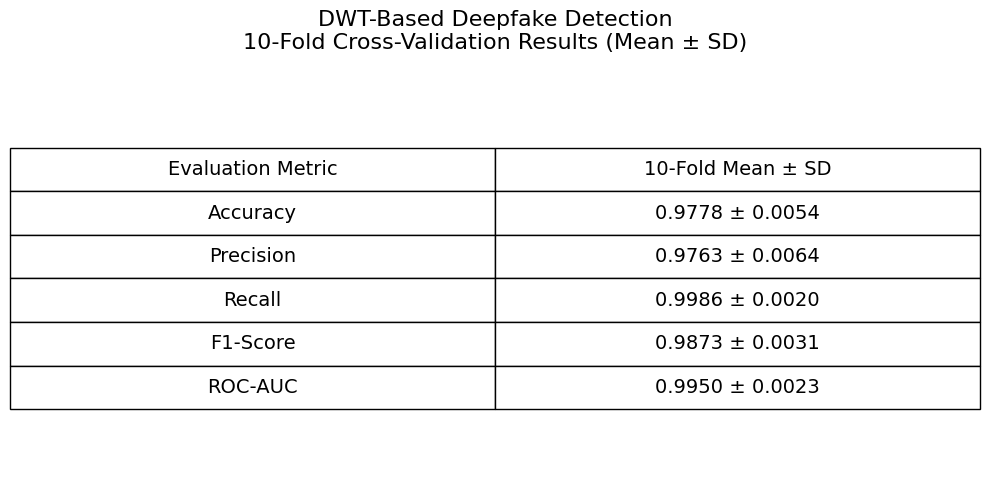


✅ FILES SAVED
CSV: /kaggle/working/DWT_10Fold_Mean_SD_Table.csv
PNG: /kaggle/working/DWT_10Fold_Mean_SD_Table.png


In [54]:
# ============================================================
# DWT 10-FOLD MEAN ± SD TABLE
# ALL AVAILABLE EVALUATION METRICS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import os

# ------------------------------------------------------------
# Check fold results
# ------------------------------------------------------------

print("Available columns:")
print(fold_results_df.columns.tolist())

# ------------------------------------------------------------
# Metrics available in our 10-fold results
# ------------------------------------------------------------

metric_map = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1-Score": "f1",
    "ROC-AUC": "auc"
}

rows = []

for metric_name, column_name in metric_map.items():

    mean_value = fold_results_df[
        column_name
    ].mean()

    std_value = fold_results_df[
        column_name
    ].std(ddof=1)

    rows.append({
        "Evaluation Metric": metric_name,
        "Mean": mean_value,
        "SD": std_value,
        "Mean ± SD":
            f"{mean_value:.4f} ± {std_value:.4f}"
    })

summary_table = pd.DataFrame(rows)

# ------------------------------------------------------------
# Display table
# ------------------------------------------------------------

print("\n==========================================")
print("DWT 10-FOLD CROSS-VALIDATION")
print("MEAN ± SD")
print("==========================================")

display(summary_table)

# ------------------------------------------------------------
# Save CSV
# ------------------------------------------------------------

csv_path = (
    "/kaggle/working/"
    "DWT_10Fold_Mean_SD_Table.csv"
)

summary_table.to_csv(
    csv_path,
    index=False
)

# ------------------------------------------------------------
# Create PNG table
# ------------------------------------------------------------

png_path = (
    "/kaggle/working/"
    "DWT_10Fold_Mean_SD_Table.png"
)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.axis("off")

table = ax.table(
    cellText=summary_table[
        [
            "Evaluation Metric",
            "Mean ± SD"
        ]
    ].values,

    colLabels=[
        "Evaluation Metric",
        "10-Fold Mean ± SD"
    ],

    cellLoc="center",

    colLoc="center",

    loc="center"
)

table.auto_set_font_size(False)

table.set_fontsize(14)

table.scale(
    1,
    2.5
)

ax.set_title(
    "DWT-Based Deepfake Detection\n"
    "10-Fold Cross-Validation Results (Mean ± SD)",
    fontsize=16,
    pad=20
)

plt.tight_layout()

plt.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n==========================================")
print("✅ FILES SAVED")
print("==========================================")

print("CSV:", csv_path)
print("PNG:", png_path)

In [55]:
from IPython.display import FileLink, display
import os

files = [
    "/kaggle/working/DWT_10Fold_Mean_SD_Table.png",
    "/kaggle/working/DWT_10Fold_Mean_SD_Table.csv"
]

for file_path in files:

    if os.path.exists(file_path):

        print("\n✅", os.path.basename(file_path))

        display(
            FileLink(
                file_path,
                result_html_prefix="📥 Download: "
            )
        )

    else:

        print(
            "❌ File not found:",
            file_path
        )


✅ DWT_10Fold_Mean_SD_Table.png


/kaggle/working/DWT_10Fold_Mean_SD_Table.png


✅ DWT_10Fold_Mean_SD_Table.csv


/kaggle/working/DWT_10Fold_Mean_SD_Table.csv

In [56]:
import os

for f in [
    "/kaggle/working/DWT_10Fold_Mean_SD_Table.png",
    "/kaggle/working/DWT_10Fold_Mean_SD_Table.csv"
]:
    print(
        os.path.basename(f),
        "→",
        "✅ EXISTS" if os.path.exists(f) else "❌ NOT FOUND"
    )

DWT_10Fold_Mean_SD_Table.png → ✅ EXISTS
DWT_10Fold_Mean_SD_Table.csv → ✅ EXISTS


In [57]:
import shutil
import os

files_to_save = [
    "/kaggle/working/DWT_10Fold_Mean_SD_Table.png",
    "/kaggle/working/DWT_10Fold_Mean_SD_Table.csv"
]

temp_dir = "/kaggle/working/DWT_Mean_SD_Table"

os.makedirs(temp_dir, exist_ok=True)

for f in files_to_save:
    if os.path.exists(f):
        shutil.copy2(
            f,
            os.path.join(
                temp_dir,
                os.path.basename(f)
            )
        )

zip_path = shutil.make_archive(
    "/kaggle/working/DWT_Mean_SD_Table",
    "zip",
    temp_dir
)

print("✅ ZIP created:")
print(zip_path)

✅ ZIP created:
/kaggle/working/DWT_Mean_SD_Table.zip
